# MFT — открытие и внутридневное продолжение движения

Пошаговое исследование IF и окончательный расчёт IF/IC/IH. Верхние ячейки — история исследования; итоговый воспроизводимый раздел исправляет лаги и добавляет полные издержки/портфельный учёт. Для запуска выполните Run All из корня проекта в окружении с requirements.txt. Основные результаты также воспроизводятся командой python -m src.project_report.

In [1]:
from src.data_loader import prepare_futures_data
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import numpy as np
from src.data_loader import prepare_futures_data
from src.bar_builder import build_15min_bars
from src.signal import add_high_volume_breakout_signal

In [2]:
if_df = prepare_futures_data("data/IF9999.CCFX.csv")
if_df = build_15min_bars(if_df)
print(if_df.head())

   session_block  group_15min               start                 end    open  \
0              0            0 2010-04-16 09:16:00 2010-04-16 09:30:00  3450.0   
1              0            1 2010-04-16 09:31:00 2010-04-16 09:45:00  3447.0   
2              0            2 2010-04-16 09:46:00 2010-04-16 10:00:00  3448.2   
3              0            3 2010-04-16 10:01:00 2010-04-16 10:15:00  3448.6   
4              0            4 2010-04-16 10:16:00 2010-04-16 10:30:00  3443.0   

     high     low   close  volume         money  open_interest  symbol  \
0  3488.0  3438.0  3446.0  3644.0  3.777728e+09         1114.0  IF1005   
1  3458.2  3443.0  3448.0  3538.0  3.660190e+09         1776.0  IF1005   
2  3449.8  3440.6  3448.6  3402.0  3.517081e+09         2119.0  IF1005   
3  3449.4  3440.2  3443.2  2629.0  2.717742e+09         2316.0  IF1005   
4  3444.4  3429.2  3431.4  3446.0  3.553641e+09         2614.0  IF1005   

   number_of_minutes  
0                 15  
1                 15  

In [3]:
print(if_df.tail())

       session_block  group_15min               start                 end  \
47491           5657            3 2021-10-18 13:46:00 2021-10-18 14:00:00   
47492           5657            4 2021-10-18 14:01:00 2021-10-18 14:15:00   
47493           5657            5 2021-10-18 14:16:00 2021-10-18 14:30:00   
47494           5657            6 2021-10-18 14:31:00 2021-10-18 14:45:00   
47495           5657            7 2021-10-18 14:46:00 2021-10-18 15:00:00   

         open    high     low   close  volume         money  open_interest  \
47491  4842.4  4842.8  4831.2  4834.8  1770.0  2.567918e+09        64498.0   
47492  4834.2  4848.2  4832.0  4847.2  2259.0  3.281533e+09        65377.0   
47493  4847.0  4852.8  4845.4  4845.8  2432.0  3.537805e+09        66560.0   
47494  4845.8  4854.6  4843.2  4846.0  2796.0  4.067918e+09        68229.0   
47495  4846.0  4861.6  4846.0  4860.0  5774.0  8.412290e+09        71872.0   

       symbol  number_of_minutes  
47491  IF2111                 15 

In [4]:
start_date_train = dt.datetime(year=2015, month=1, day=1)
end_date_train = dt.datetime(year=2018, month=12, day=31, hour=23, minute=59, second=59)
if_df_train = if_df[(if_df['end'] >= start_date_train) 
                    & (if_df['end'] <= end_date_train)].copy()

In [5]:
if_df_train['date'] = if_df_train['end'].dt.date
day_statistic = if_df_train.groupby('date').agg(
    start=('start', 'min'),
    end=('end', 'max'),
    count_bars=('start', 'count'),
    symbol_count=('symbol', 'nunique')
)
print(day_statistic.head())

                         start                 end  count_bars  symbol_count
date                                                                        
2015-01-05 2015-01-05 09:16:00 2015-01-05 15:15:00          18             1
2015-01-06 2015-01-06 09:16:00 2015-01-06 15:15:00          18             1
2015-01-07 2015-01-07 09:16:00 2015-01-07 15:15:00          18             1
2015-01-08 2015-01-08 09:16:00 2015-01-08 15:15:00          18             1
2015-01-09 2015-01-09 09:16:00 2015-01-09 15:15:00          18             1


In [6]:
print(day_statistic[day_statistic['count_bars'] != 18])

                         start                 end  count_bars  symbol_count
date                                                                        
2016-01-04 2016-01-04 09:31:00 2016-01-04 15:00:00          16             1
2016-01-05 2016-01-05 09:31:00 2016-01-05 15:00:00          16             1
2016-01-06 2016-01-06 09:31:00 2016-01-06 15:00:00          16             1
2016-01-07 2016-01-07 09:31:00 2016-01-07 15:00:00          16             1
2016-01-08 2016-01-08 09:31:00 2016-01-08 15:00:00          16             1
...                        ...                 ...         ...           ...
2018-12-24 2018-12-24 09:31:00 2018-12-24 15:00:00          16             1
2018-12-25 2018-12-25 09:31:00 2018-12-25 15:00:00          16             1
2018-12-26 2018-12-26 09:31:00 2018-12-26 15:00:00          16             1
2018-12-27 2018-12-27 09:31:00 2018-12-27 15:00:00          16             1
2018-12-28 2018-12-28 09:31:00 2018-12-28 15:00:00          16             1

In [7]:
print(day_statistic[day_statistic['symbol_count'] > 1])

                         start                 end  count_bars  symbol_count
date                                                                        
2015-01-15 2015-01-15 09:16:00 2015-01-15 15:15:00          18             2
2015-02-16 2015-02-16 09:16:00 2015-02-16 15:15:00          18             2
2015-03-19 2015-03-19 09:16:00 2015-03-19 15:15:00          18             2
2015-04-16 2015-04-16 09:16:00 2015-04-16 15:15:00          18             2
2015-05-14 2015-05-14 09:16:00 2015-05-14 15:15:00          18             2
2015-06-18 2015-06-18 09:16:00 2015-06-18 15:15:00          18             2
2015-07-16 2015-07-16 09:16:00 2015-07-16 15:15:00          18             2
2015-08-20 2015-08-20 09:16:00 2015-08-20 15:15:00          18             2
2015-09-17 2015-09-17 09:16:00 2015-09-17 15:15:00          18             2
2015-10-16 2015-10-16 09:16:00 2015-10-16 15:15:00          18             2
2015-11-19 2015-11-19 09:16:00 2015-11-19 15:15:00          18             2

In [8]:
print(if_df_train[if_df_train['date'] == dt.date(year=2015, month=1, day=15)])

       session_block  group_15min               start                 end  \
20736           2360            0 2015-01-15 09:16:00 2015-01-15 09:30:00   
20737           2360            1 2015-01-15 09:31:00 2015-01-15 09:45:00   
20738           2360            2 2015-01-15 09:46:00 2015-01-15 10:00:00   
20739           2360            3 2015-01-15 10:01:00 2015-01-15 10:15:00   
20740           2360            4 2015-01-15 10:16:00 2015-01-15 10:30:00   
20741           2360            5 2015-01-15 10:31:00 2015-01-15 10:45:00   
20742           2360            6 2015-01-15 10:46:00 2015-01-15 11:00:00   
20743           2360            7 2015-01-15 11:01:00 2015-01-15 11:15:00   
20744           2360            8 2015-01-15 11:16:00 2015-01-15 11:30:00   
20745           2361            0 2015-01-15 13:01:00 2015-01-15 13:15:00   
20746           2361            1 2015-01-15 13:16:00 2015-01-15 13:30:00   
20747           2361            2 2015-01-15 13:31:00 2015-01-15 13:45:00   

In [9]:
roll_dates = day_statistic.loc[day_statistic["symbol_count"] > 1].index
if_df_train_clean = if_df_train.loc[~if_df_train["date"].isin(roll_dates)].copy()

In [10]:
if_df_train_clean = (
    if_df_train_clean
    .sort_values(["date", "start"])
    .copy()
)

if_df_train_clean["bar_number"] = (
    if_df_train_clean
    .groupby("date")
    .cumcount()
)

bar_number_check = (
    if_df_train_clean
    .groupby("date")["bar_number"]
    .agg(["min", "max", "count"])
)

print(bar_number_check.head())
print(bar_number_check["min"].value_counts())
print(bar_number_check[["max", "count"]].value_counts())

            min  max  count
date                       
2015-01-05    0   17     18
2015-01-06    0   17     18
2015-01-07    0   17     18
2015-01-08    0   17     18
2015-01-09    0   17     18
min
0    963
Name: count, dtype: int64
max  count
15   16       731
17   18       232
Name: count, dtype: int64


In [11]:
first_bars = if_df_train_clean[if_df_train_clean['bar_number'] == 0]
print(first_bars[['date', 'start', 'end', 'symbol', 'open', 'close']])

             date               start                 end  symbol    open  \
20592  2015-01-05 2015-01-05 09:16:00 2015-01-05 09:30:00  IF1501  3619.0   
20610  2015-01-06 2015-01-06 09:16:00 2015-01-06 09:30:00  IF1501  3664.0   
20628  2015-01-07 2015-01-07 09:16:00 2015-01-07 09:30:00  IF1501  3655.8   
20646  2015-01-08 2015-01-08 09:16:00 2015-01-08 09:30:00  IF1501  3676.6   
20664  2015-01-09 2015-01-09 09:16:00 2015-01-09 09:30:00  IF1501  3570.0   
...           ...                 ...                 ...     ...     ...   
36600  2018-12-24 2018-12-24 09:31:00 2018-12-24 09:45:00  IF1901  3020.4   
36616  2018-12-25 2018-12-25 09:31:00 2018-12-25 09:45:00  IF1901  3006.8   
36632  2018-12-26 2018-12-26 09:31:00 2018-12-26 09:45:00  IF1901  3017.2   
36648  2018-12-27 2018-12-27 09:31:00 2018-12-27 09:45:00  IF1901  3043.8   
36664  2018-12-28 2018-12-28 09:31:00 2018-12-28 09:45:00  IF1901  3002.6   

        close  
20592  3608.8  
20610  3654.6  
20628  3643.8  
20646  3672

In [12]:
second_bars = if_df_train_clean[if_df_train_clean['bar_number'] == 1]
print(second_bars[['date', 'start', 'end', 'symbol', 'open', 'close']])

             date               start                 end  symbol    open  \
20593  2015-01-05 2015-01-05 09:31:00 2015-01-05 09:45:00  IF1501  3608.8   
20611  2015-01-06 2015-01-06 09:31:00 2015-01-06 09:45:00  IF1501  3654.6   
20629  2015-01-07 2015-01-07 09:31:00 2015-01-07 09:45:00  IF1501  3643.4   
20647  2015-01-08 2015-01-08 09:31:00 2015-01-08 09:45:00  IF1501  3672.0   
20665  2015-01-09 2015-01-09 09:31:00 2015-01-09 09:45:00  IF1501  3564.4   
...           ...                 ...                 ...     ...     ...   
36601  2018-12-24 2018-12-24 09:46:00 2018-12-24 10:00:00  IF1901  3021.2   
36617  2018-12-25 2018-12-25 09:46:00 2018-12-25 10:00:00  IF1901  2993.2   
36633  2018-12-26 2018-12-26 09:46:00 2018-12-26 10:00:00  IF1901  3024.8   
36649  2018-12-27 2018-12-27 09:46:00 2018-12-27 10:00:00  IF1901  3031.0   
36665  2018-12-28 2018-12-28 09:46:00 2018-12-28 10:00:00  IF1901  3003.8   

        close  
20593  3610.4  
20611  3672.8  
20629  3665.6  
20647  3656

In [13]:
last_bars = (
    if_df_train_clean
    .sort_values(["date", "bar_number"])
    .groupby("date", as_index=False)
    .tail(1)
    .copy()
)

In [14]:
first_daily = (
    first_bars[
        ["date", "close", "symbol"]
    ]
    .rename(
        columns={
            "close": "first_close",
            "symbol": "first_symbol",
        }
    )
)

entry_daily = (
    second_bars[
        ["date", "open", "symbol"]
    ]
    .rename(
        columns={
            "open": "entry_open",
            "symbol": "entry_symbol",
        }
    )
)

exit_daily = (
    last_bars[
        ["date", "close", "symbol"]
    ]
    .rename(
        columns={
            "close": "exit_close",
            "symbol": "exit_symbol",
        }
    )
)

daily_setup = (
    first_daily
    .merge(
        entry_daily,
        on="date",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        exit_daily,
        on="date",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("date")
    .reset_index(drop=True)
)

daily_setup["symbols_match"] = (
    daily_setup["first_symbol"].eq(daily_setup["entry_symbol"])
    & daily_setup["first_symbol"].eq(daily_setup["exit_symbol"])
)

print(daily_setup.head())
print(daily_setup.tail())

         date  first_close first_symbol  entry_open entry_symbol  exit_close  \
0  2015-01-05       3608.8       IF1501      3608.8       IF1501      3671.4   
1  2015-01-06       3654.6       IF1501      3654.6       IF1501      3656.8   
2  2015-01-07       3643.8       IF1501      3643.4       IF1501      3663.2   
3  2015-01-08       3672.0       IF1501      3672.0       IF1501      3562.0   
4  2015-01-09       3563.8       IF1501      3564.4       IF1501      3528.0   

  exit_symbol  symbols_match  
0      IF1501           True  
1      IF1501           True  
2      IF1501           True  
3      IF1501           True  
4      IF1501           True  
           date  first_close first_symbol  entry_open entry_symbol  \
958  2018-12-24       3022.0       IF1901      3021.2       IF1901   
959  2018-12-25       2993.8       IF1901      2993.2       IF1901   
960  2018-12-26       3024.8       IF1901      3024.8       IF1901   
961  2018-12-27       3031.0       IF1901      3031.0

In [15]:
daily_setup["prev_day_close"] = daily_setup["exit_close"].shift(1)
daily_setup["prev_day_symbol"] = daily_setup["exit_symbol"].shift(1)

daily_setup["same_contract_as_previous_day"] = (
    daily_setup["first_symbol"]
    .eq(daily_setup["prev_day_symbol"])
)


In [16]:
daily_setup_valid = daily_setup.loc[
    daily_setup["same_contract_as_previous_day"]
].copy()

daily_setup_valid["opening_move"] = (
    daily_setup_valid["first_close"]
    / daily_setup_valid["prev_day_close"]
    - 1
)

print(
    daily_setup_valid[
        [
            "date",
            "prev_day_close",
            "first_close",
            "opening_move",
            "first_symbol",
        ]
    ].head()
)

print(daily_setup_valid["opening_move"].describe())

         date  prev_day_close  first_close  opening_move first_symbol
1  2015-01-06          3671.4       3654.6     -0.004576       IF1501
2  2015-01-07          3656.8       3643.8     -0.003555       IF1501
3  2015-01-08          3663.2       3672.0      0.002402       IF1501
4  2015-01-09          3562.0       3563.8      0.000505       IF1501
5  2015-01-12          3528.0       3530.0      0.000567       IF1501
count    914.000000
mean       0.000885
std        0.008309
min       -0.053065
25%       -0.002371
50%        0.000713
75%        0.004165
max        0.071977
Name: opening_move, dtype: float64


In [17]:
daily_setup_valid['opening_move_abs'] = daily_setup_valid['opening_move'].abs()
threshold_80 = daily_setup_valid['opening_move_abs'].quantile(0.8)
print(threshold_80)

0.007810824797518703


In [18]:
print(daily_setup_valid[daily_setup_valid['opening_move'] > threshold_80].count())

date                             106
first_close                      106
first_symbol                     106
entry_open                       106
entry_symbol                     106
exit_close                       106
exit_symbol                      106
symbols_match                    106
prev_day_close                   106
prev_day_symbol                  106
same_contract_as_previous_day    106
opening_move                     106
opening_move_abs                 106
dtype: int64


In [19]:
print(daily_setup_valid[daily_setup_valid['opening_move'] < -threshold_80].count())

date                             77
first_close                      77
first_symbol                     77
entry_open                       77
entry_symbol                     77
exit_close                       77
exit_symbol                      77
symbols_match                    77
prev_day_close                   77
prev_day_symbol                  77
same_contract_as_previous_day    77
opening_move                     77
opening_move_abs                 77
dtype: int64


In [20]:
daily_setup_signal = daily_setup_valid[daily_setup_valid['opening_move'] < -threshold_80].copy()
daily_setup_signal['gross_return'] = 1 - daily_setup_signal['exit_close'] / daily_setup_signal['entry_open']
dailty_setup_signal_statistic = daily_setup_signal.agg(
    count=('gross_return', 'size'),
    median=('gross_return', 'median'),
    mean=('gross_return', 'mean'),
    win_rate=('gross_return', lambda x: (x > 0).mean()),
)
print(dailty_setup_signal_statistic)

          gross_return
count        77.000000
median        0.002054
mean          0.008032
win_rate      0.558442


In [21]:
daily_setup_signal["year"] = daily_setup_signal["date"].map(
    lambda date: date.year
)
dailty_setup_signal_statistic = daily_setup_signal.groupby('year').agg(
    count=('gross_return', 'size'),
    median=('gross_return', 'median'),
    mean=('gross_return', 'mean'),
    win_rate=('gross_return', lambda x: (x > 0).mean()),
    min=('gross_return', 'min'),
    max=('gross_return', 'max'),
    std=('gross_return', 'std'),
    sum=('gross_return', 'sum')
)
print(dailty_setup_signal_statistic)

      count    median      mean  win_rate       min       max       std  \
year                                                                      
2015     28 -0.003697  0.010927  0.464286 -0.038491  0.079443  0.032620   
2016     23  0.000064  0.005004  0.521739 -0.027576  0.054906  0.021819   
2017      3 -0.000411  0.001471  0.333333 -0.001647  0.006472  0.004374   
2018     23  0.007967  0.008391  0.739130 -0.022469  0.031653  0.013157   

           sum  
year            
2015  0.305951  
2016  0.115100  
2017  0.004414  
2018  0.192998  


In [22]:
print(daily_setup_signal.sort_values('gross_return').head())

           date  first_close first_symbol  entry_open entry_symbol  \
166  2015-09-21       3112.4       IF1510      3112.4       IF1510   
38   2015-03-09       3447.8       IF1503      3448.4       IF1503   
240  2016-01-14       3118.2       IF1601      3118.6       IF1601   
273  2016-03-08       3004.4       IF1603      3004.0       IF1603   
916  2018-10-25       3134.0       IF1811      3133.2       IF1811   

     exit_close exit_symbol  symbols_match  prev_day_close prev_day_symbol  \
166      3232.2      IF1510           True          3139.0          IF1510   
38       3564.4      IF1503           True          3490.2          IF1503   
240      3204.6      IF1601           True          3152.8          IF1601   
273      3075.4      IF1603           True          3083.8          IF1603   
916      3203.6      IF1811           True          3186.2          IF1811   

     same_contract_as_previous_day  opening_move  opening_move_abs  \
166                           True     -

In [23]:
print(daily_setup_signal.sort_values('gross_return').tail())

           date  first_close first_symbol  entry_open entry_symbol  \
117  2015-07-07       3935.0       IF1507      3935.6       IF1507   
150  2015-08-25       3011.8       IF1509      3011.8       IF1509   
149  2015-08-24       3356.2       IF1509      3356.0       IF1509   
110  2015-06-26       4514.0       IF1507      4514.4       IF1507   
130  2015-07-27       3964.0       IF1508      3962.6       IF1508   

     exit_close exit_symbol  symbols_match  prev_day_close prev_day_symbol  \
117      3696.8      IF1507           True          4040.6          IF1507   
150      2821.6      IF1509           True          3132.2          IF1509   
149      3132.2      IF1509           True          3469.2          IF1509   
110      4212.4      IF1507           True          4587.2          IF1507   
130      3647.8      IF1508           True          4012.2          IF1508   

     same_contract_as_previous_day  opening_move  opening_move_abs  \
117                           True     -

## Out-of-sample validation on 2019

The opening-move threshold is fixed using the 2015–2018 training sample. The 2019 data are processed independently with the same session, roll, entry, and exit rules.

In [24]:
def build_opening_move_setup(bars, start_date, end_date):
    period = bars.loc[
        (bars["end"] >= start_date)
        & (bars["end"] <= end_date)
    ].copy()

    period["date"] = period["end"].dt.date

    day_stats = (
        period
        .groupby("date")
        .agg(
            start=("start", "min"),
            end=("end", "max"),
            bar_count=("start", "size"),
            symbol_count=("symbol", "nunique"),
        )
    )

    roll_dates = day_stats.index[day_stats["symbol_count"] > 1]

    clean = (
        period.loc[~period["date"].isin(roll_dates)]
        .sort_values(["date", "start"])
        .copy()
    )
    clean["bar_number"] = clean.groupby("date").cumcount()

    first_bars = (
        clean.loc[
            clean["bar_number"] == 0,
            ["date", "close", "symbol"],
        ]
        .rename(columns={
            "close": "first_close",
            "symbol": "first_symbol",
        })
    )

    entry_bars = (
        clean.loc[
            clean["bar_number"] == 1,
            ["date", "open", "symbol"],
        ]
        .rename(columns={
            "open": "entry_open",
            "symbol": "entry_symbol",
        })
    )

    exit_bars = (
        clean.groupby("date", as_index=False).tail(1)
        [["date", "close", "symbol"]]
        .rename(columns={
            "close": "exit_close",
            "symbol": "exit_symbol",
        })
    )

    setup = (
        first_bars
        .merge(entry_bars, on="date", validate="one_to_one")
        .merge(exit_bars, on="date", validate="one_to_one")
        .sort_values("date")
        .reset_index(drop=True)
    )

    setup["symbols_match"] = (
        setup[["first_symbol", "entry_symbol", "exit_symbol"]]
        .nunique(axis=1)
        .eq(1)
    )

    setup["prev_day_close"] = setup["exit_close"].shift(1)
    setup["prev_day_symbol"] = setup["exit_symbol"].shift(1)
    setup["same_contract_as_previous_day"] = (
        setup["first_symbol"].eq(setup["prev_day_symbol"])
    )

    setup = setup.loc[
        setup["symbols_match"]
        & setup["same_contract_as_previous_day"]
        & setup["prev_day_close"].notna()
    ].copy()

    setup["opening_move"] = (
        setup["first_close"] / setup["prev_day_close"] - 1
    )

    return setup, day_stats, roll_dates


In [25]:
train_threshold_80 = float(threshold_80)

start_date_validation = pd.Timestamp("2019-01-01")
end_date_validation = pd.Timestamp("2019-12-31 23:59:59")

(
    if_validation_setup,
    if_validation_day_stats,
    if_validation_roll_dates,
) = build_opening_move_setup(
    if_df,
    start_date_validation,
    end_date_validation,
)

if_validation_trades = if_validation_setup.loc[
    if_validation_setup["opening_move"] < -train_threshold_80
].copy()

if_validation_trades["gross_return"] = (
    1
    - if_validation_trades["exit_close"]
    / if_validation_trades["entry_open"]
)

print("Fixed train threshold:", train_threshold_80)
print("Fixed train threshold, %:", train_threshold_80 * 100)
print("2019 calendar days:", len(if_validation_day_stats))
print("2019 roll days removed:", len(if_validation_roll_dates))
print("2019 valid setup days:", len(if_validation_setup))
print("2019 signals:", len(if_validation_trades))
print(if_validation_trades.head())


Fixed train threshold: 0.007810824797518703
Fixed train threshold, %: 0.7810824797518703
2019 calendar days: 244
2019 roll days removed: 0
2019 valid setup days: 231
2019 signals: 14
          date  first_close first_symbol  entry_open entry_symbol  exit_close  \
34  2019-02-26       3758.4       IF1903      3758.2       IF1903      3701.8   
42  2019-03-08       3734.4       IF1903      3734.6       IF1903      3673.2   
53  2019-03-25       3794.8       IF1904      3795.0       IF1904      3740.8   
79  2019-05-06       3763.8       IF1905      3764.2       IF1905      3668.0   
81  2019-05-08       3673.0       IF1905      3673.2       IF1905      3664.2   

   exit_symbol  symbols_match  prev_day_close prev_day_symbol  \
34      IF1903           True          3800.2          IF1903   
42      IF1903           True          3808.8          IF1903   
53      IF1904           True          3843.4          IF1904   
79      IF1905           True          3913.8          IF1905   
81   

In [26]:
def summarize_gross_returns(trades):
    returns = trades["gross_return"].dropna()
    standard_error = returns.std() / np.sqrt(len(returns))

    return pd.Series({
        "trades": len(returns),
        "mean_gross_return_bps": returns.mean() * 10_000,
        "median_gross_return_bps": returns.median() * 10_000,
        "win_rate_pct": (returns > 0).mean() * 100,
        "standard_error_bps": standard_error * 10_000,
        "t_statistic": returns.mean() / standard_error,
        "minimum_gross_return_pct": returns.min() * 100,
        "maximum_gross_return_pct": returns.max() * 100,
    })

if_validation_summary = summarize_gross_returns(if_validation_trades)
print(if_validation_summary)

trades                      14.000000
mean_gross_return_bps       33.692635
median_gross_return_bps     35.053439
win_rate_pct                71.428571
standard_error_bps          34.237855
t_statistic                  0.984076
minimum_gross_return_pct    -2.151228
maximum_gross_return_pct     2.555656
dtype: float64


## Окончательный воспроизводимый расчёт

Ниже — единый расчёт IF/IC/IH и сравнение двух сигналов. Верхняя часть ноутбука сохранена как история пошагового исследования: её ранняя очистка удаляла смешанные дни **до** lag, а комиссии и размер позиций ещё не учитывались. Для вывода используются только итоговые таблицы ниже.

Предыдущее закрытие теперь вычисляется по всем исходным дням до фильтрации. Добавлены проверка полноты сессии, целое число контрактов, общий бюджет риска/маржи, переоценка по минутным close и сравнение сценариев комиссий. Основной сценарий historical_proxy — документированная реконструкция тарифов, с ограничениями, описанными в отчёте. Один тик проскальзывания применяется **на каждую сторону**.

Train: 2015–2018; validation: 2019; test: 2020 до фактического конца данных. Эти периоды уже просматривались, поэтому слово test обозначает хронологический срез, а не нетронутый holdout. Параметры не подбираются по итогам этого запуска.

In [27]:
from src.opening_move_final import run_opening_move_research

opening_results = run_opening_move_research(
    data_dir="data",
    signal_quantile=0.80,
    slippage_ticks=1,  # один тик НА КАЖДУЮ СТОРОНУ
    initial_capital=3_000_000,
    risk_fraction=0.005,  # оценочный риск; это не stop-loss
    max_trade_margin_fraction=0.20,
    max_portfolio_margin_fraction=0.60,
    max_contracts=20,
    fee_scenario="historical_proxy",
)
display(opening_results["coverage"])
display(opening_results["thresholds"])
display(opening_results["data_audit"])
print("Параметры:", opening_results["config"])

,instrument,rows,bars,first_date,last_date
0,IF,712440,47496,2010-04-16 09:16:00,2021-10-18 15:00:00
1,IC,385470,25698,2015-04-16 09:16:00,2021-10-18 15:00:00
2,IH,385470,25698,2015-04-16 09:16:00,2021-10-18 15:00:00


,instrument,strategy,quantile,threshold,threshold_pct,train_observations
0,IC,opening,0.8,0.009129,0.912928,863
1,IF,opening,0.8,0.007871,0.787063,927
2,IH,opening,0.8,0.007868,0.786828,863
3,IF,momentum,0.8,0.007282,0.728208,10094
4,IC,momentum,0.8,0.009208,0.920814,9338
5,IH,momentum,0.8,0.006693,0.669302,9338


observed_days  eligible_days  mixed_contract_days  \
period     instrument                                                      
test       IC                    432            410                    0   
           IF                    432            410                    0   
           IH                    432            410                    0   
train      IC                    908            863                    8   
           IF                    975            927                   12   
           IH                    908            863                    8   
validation IC                    244            232                    0   
           IF                    244            232                    0   
           IH                    244            232                    0   

                       incomplete_days  raw_signals  accepted_trades  
period     instrument                                                 
test       IC                        0           30                9  
           IF                        0           42               10  
           IH                        0           52               34  
train      IC                        0           87               23  
           IF                        0           78               28  
           IH                        0           67               36  
validation IC                        0           18               11  
           IF                        0           14                7  
           IH                        0           18               13

Параметры: {'signal_quantile': 0.8, 'slippage_ticks_per_side': 1, 'initial_capital': 3000000, 'risk_fraction': 0.005, 'max_trade_margin_fraction': 0.2, 'max_portfolio_margin_fraction': 0.6, 'max_contracts': 20, 'fee_scenario': 'historical_proxy', 'max_portfolio_risk_fraction': 0.015, 'volatility_window': 20, 'volatility_min_observations': 15, 'volatility_floor': 0.001, 'bootstrap_seed': 42, 'bootstrap_repetitions': 1000, 'bootstrap_block_days': 5}


In [28]:
print("Trade-level results after costs and sizing:")
display(opening_results["trade_summary"])

print("Portfolio equity results:")
display(opening_results["equity_summary"])

Trade-level results after costs and sizing:


,trades,mean_net_payoff_bps,median_net_payoff_bps,win_rate_pct,total_net_pnl_cny,naive_trade_t_statistic
period,,,,,,
train,87.0,33.036925,26.380287,57.471264,309274.09710,1.836619
validation,31.0,-30.571209,-27.015834,45.161290,-97217.63158,-1.450942
test,53.0,6.210925,-7.543659,47.169811,57320.65376,0.314633


Portfolio equity results:


,first_date,last_date,trading_days,start_equity_cny,end_equity_cny,total_return_pct,annualized_return_pct,annualized_sharpe,max_drawdown_pct,trades,win_rate_pct,minute_close_max_drawdown_pct,maximum_margin_usage_pct,margin_cap_breach_events
train,2015-01-05 00:00:00,2018-12-28 00:00:00,975,3000000,3309274.0971,10.309137,2.495349,0.753279,-3.455998,87,57.471264,-4.060727,48.804538,0
validation,2019-01-02 00:00:00,2019-12-31 00:00:00,244,3000000,2902782.36842,-3.240588,-3.251533,-0.978893,-5.066062,31,45.16129,-5.851198,16.870461,0
test,2020-01-02 00:00:00,2021-10-18 00:00:00,432,3000000,3057320.65376,1.910688,1.059376,0.282414,-2.696427,53,47.169811,-3.285818,15.006333,0


In [29]:
print("Results by period and instrument:")
display(opening_results["instrument_period_summary"])

print("Results by calendar year:")
display(opening_results["yearly_summary"])

Results by period and instrument:


trades  mean_net_payoff_bps  median_net_payoff_bps  \
period     instrument                                                       
test       IC             9.0           -42.194511             -77.467006   
           IF            10.0            52.963476              24.174555   
           IH            34.0             5.273378              -6.837404   
train      IC            23.0            53.094323              57.454212   
           IF            28.0            35.381671              15.491071   
           IH            36.0            18.398785              13.557667   
validation IC            11.0           -21.290651              12.366381   
           IF             7.0           -51.017861             -60.718898   
           IH            13.0           -27.414252             -27.015834   

                       win_rate_pct  total_net_pnl_cny  \
period     instrument                                    
test       IC             44.444444       -56910.47244   
           IF             50.000000        67631.43142   
           IH             47.058824        46599.69478   
train      IC             65.217391       130998.35052   
           IF             57.142857       115007.54904   
           IH             52.777778        63268.19754   
validation IC             54.545455       -17684.97180   
           IF             42.857143       -39012.68828   
           IH             38.461538       -40519.97150   

                       naive_trade_t_statistic  
period     instrument                           
test       IC                        -0.933167  
           IF                         0.969052  
           IH                         0.225256  
train      IC                         1.371413  
           IF                         1.207102  
           IH                         0.654450  
validation IC                        -0.460010  
           IF                        -1.200354  
           IH                        -1.097368

Results by calendar year:


trades  mean_net_payoff_bps  median_net_payoff_bps  \
period     year                                                       
test       2020    26.0            10.871087              -1.501771   
           2021    27.0             1.723361             -11.130548   
train      2015     6.0          -148.663334            -126.488902   
           2016    26.0            -3.780045             -28.724183   
           2017    11.0             1.265726              33.248108   
           2018    44.0            87.512515              91.334004   
validation 2019    31.0           -30.571209             -27.015834   

                 win_rate_pct  total_net_pnl_cny  naive_trade_t_statistic  
period     year                                                            
test       2020     50.000000        49841.18626                 0.320989  
           2021     44.444444         7479.46750                 0.079815  
train      2015     33.333333       -73836.45916                -1.681950  
           2016     38.461538        -9870.78976                -0.123305  
           2017     54.545455         3319.68514                 0.035512  
           2018     72.727273       389661.66088                 3.695623  
validation 2019     45.161290       -97217.63158                -1.450942

In [30]:
print("Payoff всех сигналов по одному контракту (до портфельного отбора):")
display(opening_results["robustness"].pivot_table(
    index=["quantile", "slippage_ticks"], columns="period",
    values=["trades", "mean_net_payoff_bps", "win_rate_pct"],
))
print("Сценарии комиссий: legacy, историческая реконструкция, буквальные ‰ Excel:")
display(opening_results["cost_sensitivity"])
print("95%-й интервал среднего дневного PnL: блоки 5 дней, seed=42, 1000 повторов.")
display(opening_results["confidence_intervals"])

Payoff всех сигналов по одному контракту (до портфельного отбора):


mean_net_payoff_bps                       trades  \
period                                 test      train validation   test   
quantile slippage_ticks                                                    
0.7      1                        13.399475  48.102796  15.455549  199.0   
         2                        12.429213  46.950516  14.378534  199.0   
         3                        11.458951  45.798237  13.301520  199.0   
0.8      1                        24.016387  56.058103  17.727757  124.0   
         2                        23.034797  54.936289  16.620562  124.0   
         3                        22.053208  53.814476  15.513368  124.0   
0.9      1                        38.268535  60.839661  44.695407   52.0   
         2                        37.252577  59.676712  43.528912   52.0   
         3                        36.236618  58.513762  42.362417   52.0   

                                          win_rate_pct                        
period                   train validation         test      train validation  
quantile slippage_ticks                                                       
0.7      1               318.0       78.0    51.758794  52.830189  61.538462  
         2               318.0       78.0    51.256281  52.201258  61.538462  
         3               318.0       78.0    49.748744  51.886792  61.538462  
0.8      1               232.0       50.0    53.225806  52.586207  60.000000  
         2               232.0       50.0    53.225806  52.155172  60.000000  
         3               232.0       50.0    52.419355  51.724138  60.000000  
0.9      1               129.0       28.0    57.692308  50.387597  67.857143  
         2               129.0       28.0    57.692308  49.612403  67.857143  
         3               129.0       28.0    55.769231  49.612403  67.857143

Сценарии комиссий: legacy, историческая реконструкция, буквальные ‰ Excel:


,fee_scenario,period,trades,mean_net_payoff_bps,median_net_payoff_bps,win_rate_pct,total_net_pnl_cny,naive_trade_t_statistic
0,legacy_constant,train,232.0,64.017455,21.516896,54.741379,1.736606e+06,3.387448
1,legacy_constant,validation,50.0,17.978512,19.784948,60.000000,9.565826e+04,0.945414
2,legacy_constant,test,124.0,24.016387,5.172710,53.225806,3.557349e+05,1.837847
3,historical_proxy,train,232.0,56.058103,13.614470,52.586207,1.556299e+06,2.945663
4,historical_proxy,validation,50.0,17.727757,19.784948,60.000000,9.443027e+04,0.933088
5,historical_proxy,test,124.0,24.016387,5.172710,53.225806,3.557349e+05,1.837847
6,workbook_per_mille,train,232.0,31.109494,-11.522796,48.275862,9.507931e+05,1.641048
7,workbook_per_mille,validation,50.0,-15.072364,-13.260586,44.000000,-6.491744e+04,-0.790139
8,workbook_per_mille,test,124.0,-9.015966,-27.917574,41.129032,-1.223188e+05,-0.687809


95%-й интервал среднего дневного PnL: блоки 5 дней, seed=42, 1000 повторов.


,period,mean_daily_pnl_cny,block_bootstrap_low_cny,block_bootstrap_high_cny
0,train,317.204202,-108.488940,794.451583
1,validation,-398.432916,-1271.308299,347.849745
2,test,132.686699,-486.241767,849.370764


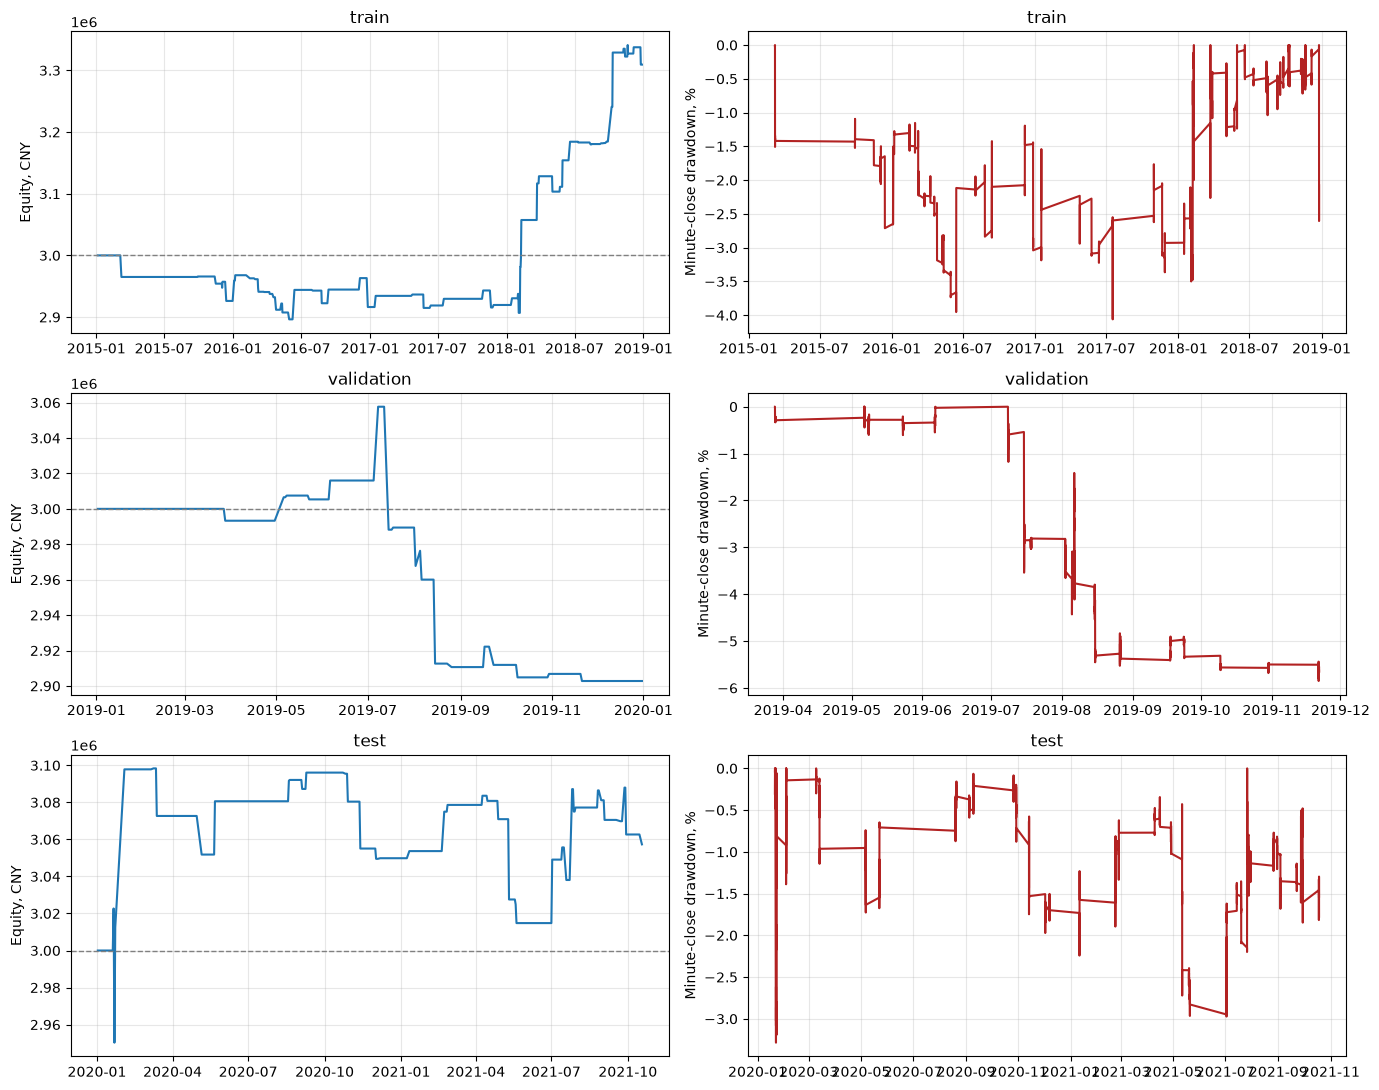

In [31]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11))
for i, period in enumerate(["train", "validation", "test"]):
    daily = opening_results["equity_curves"][period]
    marks = opening_results["minute_equity"][period]
    axes[i, 0].plot(daily.index, daily["equity_cny"])
    axes[i, 0].axhline(3_000_000, color="gray", linestyle="--", linewidth=1)
    axes[i, 0].set(title=period, ylabel="Equity, CNY")
    axes[i, 1].plot(marks["time"], marks["drawdown"] * 100, color="firebrick")
    axes[i, 1].set(title=period, ylabel="Minute-close drawdown, %")
    for ax in axes[i]:
        ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
print("Целевые метрики: доходность >20%, Sharpe >1.5, минутная просадка <15%.")
display(opening_results["goal_check"][[
    "annualized_return_pct", "annualized_sharpe", "max_drawdown_pct",
    "minute_close_max_drawdown_pct", "win_rate_pct",
    "return_above_20pct", "sharpe_above_1_5", "drawdown_below_15pct",
    "win_rate_above_50pct", "required_goals_pass",
]])
print("Пропуски после оценки размера позиции:")
display(opening_results["allocated_trades"].groupby(["period", "skip_reason"]).size())
print("Максимальная доля маржи и нарушения после переоценки:")
display(opening_results["equity_summary"][[
    "maximum_margin_usage_pct", "margin_cap_breach_events",
]])

Целевые метрики: доходность >20%, Sharpe >1.5, минутная просадка <15%.


,annualized_return_pct,annualized_sharpe,max_drawdown_pct,minute_close_max_drawdown_pct,win_rate_pct,return_above_20pct,sharpe_above_1_5,drawdown_below_15pct,win_rate_above_50pct,required_goals_pass
train,2.495349,0.753279,-3.455998,-4.060727,57.471264,False,False,True,True,False
validation,-3.251533,-0.978893,-5.066062,-5.851198,45.16129,False,False,True,False,False
test,1.059376,0.282414,-2.696427,-3.285818,47.169811,False,False,True,False,False


Пропуски после оценки размера позиции:


period      skip_reason             
test                                     53
            risk_margin_or_daily_cap     71
train                                    87
            risk_margin_or_daily_cap    142
            volatility_warmup             3
validation                               31
            risk_margin_or_daily_cap     19
dtype: int64

Максимальная доля маржи и нарушения после переоценки:


,maximum_margin_usage_pct,margin_cap_breach_events
train,48.804538,0
validation,16.870461,0
test,15.006333,0


## Сравнение с часовым сигналом

Часовой short-momentum пересчитан на тех же IF/IC/IH, с входом на следующий open, общими издержками, оценкой размера позиции и минутной переоценкой. Он отличается от прежнего ноутбука 03 (там также RU и вход по close). Комбинация принимает сигналы обоих типов и не открывает две позиции одного инструмента одновременно; параметры общие и фиксированы. Оба сигнала торгуют падение индексов, поэтому их нельзя заранее считать независимыми.

,strategy,period,annualized_return_pct,annualized_sharpe,minute_close_max_drawdown_pct,trades,win_rate_pct
0,opening,train,2.495349,0.753279,-4.060727,87,57.471264
1,opening,validation,-3.251533,-0.978893,-5.851198,31,45.161290
2,opening,test,1.059376,0.282414,-3.285818,53,47.169811
3,momentum_indices,train,-0.853268,-0.527890,-6.708752,173,45.664740
4,momentum_indices,validation,-1.968786,-1.639603,-3.058162,43,23.255814
5,momentum_indices,test,1.747586,1.111590,-1.909391,99,52.525253
6,combined_indices,train,2.418046,0.652607,-8.036386,229,51.965066
7,combined_indices,validation,-4.951851,-1.418494,-6.462461,63,31.746032
8,combined_indices,test,1.721761,0.430200,-3.299119,125,48.800000


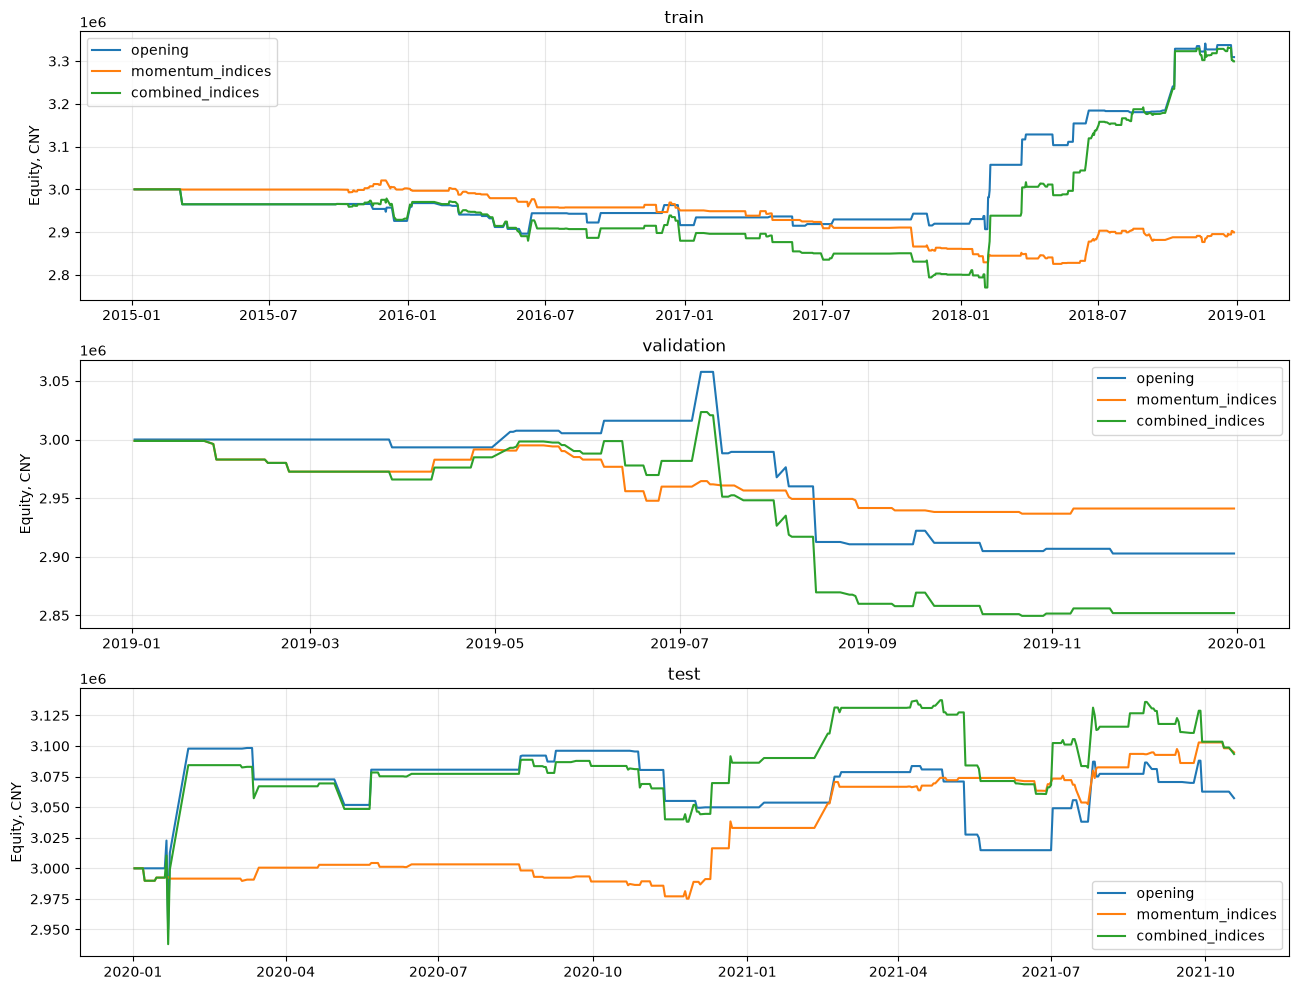

In [33]:
columns = ["strategy", "period", "annualized_return_pct", "annualized_sharpe",
           "minute_close_max_drawdown_pct", "trades", "win_rate_pct"]
display(opening_results["comparison"][columns])
fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, period in zip(axes, ["train", "validation", "test"]):
    for book in ["opening", "momentum_indices", "combined_indices"]:
        daily = opening_results["comparison_curves"][(book, period)]
        ax.plot(daily.index, daily["equity_cny"], label=book)
    ax.set(title=period, ylabel="Equity, CNY")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Концентрация прибыли и сверка расчёта

Статистика сделок выражает payoff к номиналу контракта; портфельные метрики учитывают капитал и число контрактов. Таблица ниже показывает лучших/худших сделок и вклад пяти лучших в фактический PnL. Это диагностика концентрации, а не тест новой стратегии с удалёнными победителями.

In [34]:
accepted = opening_results["accepted_trades"]
trade_columns = ["date", "instrument", "entry_time", "exit_time", "entry_open",
                 "exit_close", "contracts", "net_return", "portfolio_pnl_cny"]
display(accepted.nsmallest(5, "portfolio_pnl_cny")[trade_columns])
display(accepted.nlargest(5, "portfolio_pnl_cny")[trade_columns])
concentration = []
for period, trades in accepted.groupby("period"):
    best_five = trades.nlargest(5, "portfolio_pnl_cny")["portfolio_pnl_cny"].sum()
    total = trades["portfolio_pnl_cny"].sum()
    concentration.append({"period": period, "total_pnl_cny": total,
                          "best_5_pnl_cny": best_five,
                          "pnl_excluding_best_5_cny": total - best_five})
    daily = opening_results["equity_curves"][period]
    marks = opening_results["minute_equity"][period]
    assert np.isclose(total, daily["equity_cny"].iloc[-1] - 3_000_000)
    assert np.isclose(total, marks["equity_cny"].iloc[-1] - 3_000_000)
    assert not trades.duplicated(["date", "instrument"]).any()
    assert (trades["signal_time"] < trades["entry_time"]).all()
display(pd.DataFrame(concentration))
print("PnL сделок, дневной капитал и минутная переоценка совпадают.")

,date,instrument,entry_time,exit_time,entry_open,exit_close,contracts,net_return,portfolio_pnl_cny
3,2015-03-09,IF,2015-03-09 09:31:00,2015-03-09 15:15:00,3448.4,3564.4,1,-0.033806,-34972.59600
284,2020-01-22,IC,2020-01-22 09:46:00,2020-01-22 15:00:00,5422.8,5580.8,1,-0.029590,-32092.03296
86,2015-12-14,IH,2015-12-14 09:31:00,2015-12-14 15:15:00,2316.2,2413.8,1,-0.044734,-31083.64040
259,2019-07-15,IC,2019-07-15 09:46:00,2019-07-15 15:00:00,4757.6,4906.0,1,-0.031657,-30122.41184
153,2016-12-26,IH,2016-12-26 09:46:00,2016-12-26 15:00:00,2240.4,2283.0,2,-0.021561,-28983.73076


,date,instrument,entry_time,exit_time,entry_open,exit_close,contracts,net_return,portfolio_pnl_cny
208,2018-10-11,IC,2018-10-11 09:46:00,2018-10-11 15:00:00,4490.0,4258.2,1,0.050857,45669.68772
169,2018-02-06,IC,2018-02-06 09:46:00,2018-02-06 15:00:00,5899.2,5686.8,1,0.035247,41586.05860
290,2020-02-03,IF,2020-02-03 09:46:00,2020-02-03 15:00:00,3727.0,3591.2,1,0.035972,40220.57518
174,2018-02-09,IF,2018-02-09 09:46:00,2018-02-09 15:00:00,3904.8,3781.2,1,0.030858,36148.30846
178,2018-03-23,IC,2018-03-23 09:46:00,2018-03-23 15:00:00,5850.2,5665.6,1,0.030793,36029.20960


,period,total_pnl_cny,best_5_pnl_cny,pnl_excluding_best_5_cny
0,test,57320.65376,164964.84218,-107644.18842
1,train,309274.09710,192479.51614,116794.58096
2,validation,-97217.63158,70249.88982,-167467.52140


PnL сделок, дневной капитал и минутная переоценка совпадают.


## Итог и ограничения

Выполнение всех требований проверяется по required_goals_pass, без подгонки плеча и порога под test. Слабые результаты validation, небольшое число сделок, зависимость IF/IC/IH и концентрация прибыли ограничивают выводы. Корректный отрицательный результат тоже является законченным исследованием.

Фильтрация неполных дней и дней с несколькими symbol использует полную дневную запись: это ex-post экран качества данных. Для живой стратегии потребуется заранее известный выбор контракта/календарь роллов. Open/close минутного бара не гарантируют исполнение, особенно на лимитах; нет bid/ask, очереди, брокерской истории тарифов и точного клиринга. Минутная просадка может пропускать худшую цену внутри минуты. Эти ограничения не устраняются положительным средним payoff.

Полный отчёт, таблицы, список принятых и пропущенных сигналов, графики и параметры запуска сохраняются следующей ячейкой. Финальные выводы автоматически формируются из результатов.

In [35]:
from src.project_report import export_results
from IPython.display import Markdown, display

report_dir = export_results(opening_results, output_dir="reports", data_dir="data")
print("Результаты сохранены:", report_dir.resolve())
display(Markdown((report_dir / "OPENING_INDICES_REPORT.md").read_text(encoding="utf-8")))

Результаты сохранены: /home/egorzobkov/cmf/MFT_HW/reports


# Итоговый исследовательский отчёт MFT

Проект завершён как воспроизводимое исследование стратегий. Проверенные варианты
не подтверждают выполнение всех целевых требований. Положительное среднее на одну
сделку нельзя приравнивать к годовой доходности капитала или к доказанной стратегии.

## Данные и воспроизведение

Использованы исходные минутные IF, IC, IH. Исторические ноутбуки 01–04 сохранены.
Ноутбук 05 содержит обучение на IF и окончательный общий расчёт. Единый расчёт:
`python -m src.project_report`. Проверки: `python -m unittest discover -s tests -v`.
Все таблицы, сделки, минутная переоценка и SHA256 исходных файлов находятся рядом
с этим отчётом. Отчёт строится автоматически из фактических результатов.

| instrument | rows | bars | first_date | last_date |
| --- | --- | --- | --- | --- |
| IF | 712440 | 47496 | 2010-04-16 09:16:00 | 2021-10-18 15:00:00 |
| IC | 385470 | 25698 | 2015-04-16 09:16:00 | 2021-10-18 15:00:00 |
| IH | 385470 | 25698 | 2015-04-16 09:16:00 | 2021-10-18 15:00:00 |

Train — 2015–2018, validation — 2019, test — 2020 до фактического конца данных
2021-10-18. Периоды уже просматривались в ходе исследования: test здесь название
хронологического среза, а не нетронутая контрольная выборка. Каждый период начинает
с отдельного капитала 3 млн CNY. Три кривые нельзя склеить как единую историю счёта.

## Правила стратегии открытия

Закрытие первого 15-минутного бара сравнивается с фактическим закрытием предыдущего
торгового дня того же контракта. Если движение меньше отрицательного 80-го
процентиля абсолютных движений train, следующая свеча используется для входа short
по open. Выход — последнее закрытие дневной сессии. Порог фиксирован для каждого
инструмента. Сессии принимаются в наблюдаемых раскладках 18/16 полных баров.
Лаг предыдущего дня вычисляется до удаления неполных и смешанных дней.

| instrument | strategy | quantile | threshold | threshold_pct | train_observations |
| --- | --- | --- | --- | --- | --- |
| IC | opening | 0.800 | 0.009 | 0.913 | 863 |
| IF | opening | 0.800 | 0.008 | 0.787 | 927 |
| IH | opening | 0.800 | 0.008 | 0.787 | 863 |
| IF | momentum | 0.800 | 0.007 | 0.728 | 10094 |
| IC | momentum | 0.800 | 0.009 | 0.921 | 9338 |
| IH | momentum | 0.800 | 0.007 | 0.669 | 9338 |

Размер позиции — целое число контрактов по 0,5% от меньшего из начального и
текущего капитала, делённым на оценку риска одного контракта. Риск — стандартное
отклонение дневных доходностей за 20 прошлых дней (минимум 15 наблюдений), известное
до открытия. Оценка имеет нижнюю границу 0,1%. Лимиты: 20% капитала на маржу одной
позиции, 60% суммарно, 1,5% суммарного оценочного риска и максимум 20 контрактов,
с дополнительным консервативным лимитом 10 контрактов в ограниченном режиме
2015-09-07–2017-02-16. Если один контракт не помещается в бюджет, сделки нет.
0,5% — правило размера, не стоп-лосс и не гарантия максимального убытка.
На одном инструменте одновременно допускается одна позиция, без пирамидинга.
Одновременные входы обрабатываются по имени инструмента; это фиксированный порядок,
не оптимизация по результатам. Маржа переоценивается на каждом минутном close.

## Издержки и расхождения с прежними результатами

1 bp = 0,01%; 1‰ = 0,1% = 10 bp. Excel содержит 0,23‰ и 3,45‰, что буквально
соответствует 2,3 и 34,5 bp. Старый код использовал 0,23 и 3,45 bp.
Числа из таблицы Excel поэтому не являются подтверждённой историей тарифа.

Основной сценарий historical_proxy восстанавливает тариф открытия 0,25 bp до
2015-08-03, затем 0,23 bp; закрытие в тот же день: обычный тариф до 2015-08-26,
затем 1,15 bp, с 2015-09-07 — 23 bp, с 2017-02-17 — 9,2 bp,
с 2017-09-18 — 6,9 bp, с 2018-12-03 — 4,6 bp и с 2019-04-22 — 3,45 bp.
Также учтён сценарный сбор 1 CNY за каждую из двух поданных заявок с 2015-08-03.
Маржа: консервативные 40% до 2017-02-20; далее IF/IH 20%, затем 15%, с
2018-12-04 — 10%; IC 30%, с 2018-12-04 — 15%, с 2019-04-23 — 12%.
Это реконструкция основных режимов и консервативные допущения ранней маржи;
брокерские надбавки, все промежуточные изменения, особые параметры экспирации и
клиентские ограничения полностью не восстановлены. Нельзя назвать её точным
историческим моделированием исполнения и клиринга.

Источники для проверки: [раскрытие CFFEX 2024](https://www.cffex.com.cn/cn/zjssf/20240701/39212.html),
[исследование изменений правил Huatai](https://www.htfc.com/wz_upload/png_upload/20200827/15985190946611d21b3.pdf),
[уведомление о режиме сентября 2015](https://cfc108.com/zxjtqh/2015-09/05/article_414101.shtml),
[изменения декабря 2018](https://www.bhfcc.com/customer-center-ques-details.html?id=2095),
[публикация уведомления апреля 2019](https://www.qhfco.net/customer-service/trading-guide/trading-notice/494460d8-518b-11f0-89c7-b8e92477e4ec).
Тариф CFFEX 2024 приведён для проверки единиц и не применяется ретроспективно.

Проскальзывание основного расчёта — один тик на каждую сторону, то есть два тика
за полный круг. Комиссия считается от цены исполнения каждой стороны, PnL от
мультипликатора IF/IH 300, IC 200. Сравнение сценариев ниже на один контракт,
до портфельного отбора и размера позиций:

| fee_scenario | period | trades | mean_net_payoff_bps | median_net_payoff_bps | win_rate_pct | total_net_pnl_cny | naive_trade_t_statistic |
| --- | --- | --- | --- | --- | --- | --- | --- |
| legacy_constant | train | 232.000 | 64.017 | 21.517 | 54.741 | 1736605.511 | 3.387 |
| legacy_constant | validation | 50.000 | 17.979 | 19.785 | 60.000 | 95658.256 | 0.945 |
| legacy_constant | test | 124.000 | 24.016 | 5.173 | 53.226 | 355734.921 | 1.838 |
| historical_proxy | train | 232.000 | 56.058 | 13.614 | 52.586 | 1556298.736 | 2.946 |
| historical_proxy | validation | 50.000 | 17.728 | 19.785 | 60.000 | 94430.270 | 0.933 |
| historical_proxy | test | 124.000 | 24.016 | 5.173 | 53.226 | 355734.921 | 1.838 |
| workbook_per_mille | train | 232.000 | 31.109 | -11.523 | 48.276 | 950793.109 | 1.641 |
| workbook_per_mille | validation | 50.000 | -15.072 | -13.261 | 44.000 | -64917.440 | -0.790 |
| workbook_per_mille | test | 124.000 | -9.016 | -27.918 | 41.129 | -122318.791 | -0.688 |

## Итоги портфеля открытия

| index | annualized_return_pct | annualized_sharpe | max_drawdown_pct | minute_close_max_drawdown_pct | trades | win_rate_pct | maximum_margin_usage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- |
| train | 2.495 | 0.753 | -3.456 | -4.061 | 87 | 57.471 | 48.805 |
| validation | -3.252 | -0.979 | -5.066 | -5.851 | 31 | 45.161 | 16.870 |
| test | 1.059 | 0.282 | -2.696 | -3.286 | 53 | 47.170 | 15.006 |

Годовая доходность — CAGR по фактическим календарным датам покрытия; Sharpe —
среднее/стандартное отклонение дневных доходностей × sqrt(252), ставка без риска 0.
В дневном календаре только наблюдаемые торговые даты, включая дни без сделок.
Просадка отсчитывается также от начальных 3 млн, чтобы первый убыток не исчезал.
Дневная и минутная просадки показаны раздельно. Минутная использует close и может
пропускать худшие движения внутри минуты. PnL сделок сверяется с итогом переоценки.

Средний payoff всех сигналов по одному контракту и доходность итогового портфеля
могут иметь разный знак. Правило размера пропускает часть сигналов, если один
контракт слишком велик для бюджета, и назначает разное число контрактов остальным.
В 2019 эта разница существенна: положительное среднее всех сигналов не сохранилось
в фактическом портфеле. Таблицы allocated_trades.csv и cost_sensitivity.csv позволяют
проверить это напрямую. Порог и размер не меняются ради исправления результата.

![Капитал и просадка](equity_drawdown.png)

| period | year | trades | mean_net_payoff_bps | median_net_payoff_bps | win_rate_pct | total_net_pnl_cny | naive_trade_t_statistic |
| --- | --- | --- | --- | --- | --- | --- | --- |
| test | 2020 | 26.000 | 10.871 | -1.502 | 50.000 | 49841.186 | 0.321 |
| test | 2021 | 27.000 | 1.723 | -11.131 | 44.444 | 7479.468 | 0.080 |
| train | 2015 | 6.000 | -148.663 | -126.489 | 33.333 | -73836.459 | -1.682 |
| train | 2016 | 26.000 | -3.780 | -28.724 | 38.462 | -9870.790 | -0.123 |
| train | 2017 | 11.000 | 1.266 | 33.248 | 54.545 | 3319.685 | 0.036 |
| train | 2018 | 44.000 | 87.513 | 91.334 | 72.727 | 389661.661 | 3.696 |
| validation | 2019 | 31.000 | -30.571 | -27.016 | 45.161 | -97217.632 | -1.451 |

## Сравнение и комбинация

Часовой сигнал пересчитан на одинаковой вселенной IF/IC/IH: отрицательное движение
за четыре бара выше train-порога по модулю, вход на следующем open и выход после
четырёх баров внутри той же непрерывной сессии. Это исправленная сопоставимая
версия, отличающаяся от старого ноутбука 03, где также был RU и вход по close.
RU не включён в это сравнение, чтобы не смешивать календари и схемы комиссий.
Комбинация принимает оба сигнала с общими лимитами, запрещает пересечение позиций
одного инструмента и не использует будущую прибыль для выбора сигнала.

| strategy | period | annualized_return_pct | annualized_sharpe | max_drawdown_pct | minute_close_max_drawdown_pct | trades | win_rate_pct | maximum_margin_usage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| opening | train | 2.495 | 0.753 | -3.456 | -4.061 | 87 | 57.471 | 48.805 |
| opening | validation | -3.252 | -0.979 | -5.066 | -5.851 | 31 | 45.161 | 16.870 |
| opening | test | 1.059 | 0.282 | -2.696 | -3.286 | 53 | 47.170 | 15.006 |
| momentum_indices | train | -0.853 | -0.528 | -6.459 | -6.709 | 173 | 45.665 | 49.421 |
| momentum_indices | validation | -1.969 | -1.640 | -2.109 | -3.058 | 43 | 23.256 | 11.136 |
| momentum_indices | test | 1.748 | 1.112 | -0.972 | -1.909 | 99 | 52.525 | 14.683 |
| combined_indices | train | 2.418 | 0.653 | -7.655 | -8.036 | 229 | 51.965 | 50.256 |
| combined_indices | validation | -4.952 | -1.418 | -5.749 | -6.462 | 63 | 31.746 | 17.110 |
| combined_indices | test | 1.722 | 0.430 | -2.444 | -3.299 | 125 | 48.800 | 15.069 |

![Сравнение стратегий](strategy_comparison.png)

## Статистика и устойчивость

Средние, медианы и win rate в таблицах сделок относятся к фактически принятым
сделкам после издержек. Payoff — доля номинала контракта, не доходность маржи или
счёта. Наивный trade t-statistic только описательный: IF/IC/IH зависимы.
Для среднего дневного PnL дополнительно рассчитан воспроизводимый 95%-й интервал
блочным bootstrap (блок 5 торговых дней, 1000 повторов, seed 42), с одновременным
объединением инструментов по дню и включением нулевых дней. Интервал не исправляет
множественный перебор идей и просмотр контрольных данных.

| period | mean_daily_pnl_cny | block_bootstrap_low_cny | block_bootstrap_high_cny |
| --- | --- | --- | --- |
| train | 317.204 | -108.489 | 794.452 |
| validation | -398.433 | -1271.308 | 347.850 |
| test | 132.687 | -486.242 | 849.371 |

Таблица robustness.csv проверяет train-квантили 70/80/90% и 1/2/3 тика на сторону.
Это диагностика payoff всех сигналов по одному контракту, а не повторный подбор
оптимальных параметров капитала на test. Средние взвешены числом сделок через
агрегацию самих сделок, а не равными весами инструментов.

## Проверка задания и вывод

| index | annualized_return_pct | annualized_sharpe | max_drawdown_pct | minute_close_max_drawdown_pct | trades | win_rate_pct | maximum_margin_usage_pct | return_above_20pct | sharpe_above_1_5 | drawdown_below_15pct | required_goals_pass |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| train | 2.495 | 0.753 | -3.456 | -4.061 | 87 | 57.471 | 48.805 | False | False | True | False |
| validation | -3.252 | -0.979 | -5.066 | -5.851 | 31 | 45.161 | 16.870 | False | False | True | False |
| test | 1.059 | 0.282 | -2.696 | -3.286 | 53 | 47.170 | 15.006 | False | False | True | False |

Цели: годовая доходность >20%, Sharpe >1,5, максимальная просадка <15%; win rate
>50% — дополнительная метрика. На показанных хронологических срезах стратегия
не удовлетворяет всем обязательным условиям. Комбинация также должна оцениваться
по таблице выше, а не по прежним иллюстративным числам. Законченный исследовательский
результат — неподтверждённый кандидат, а не обещание прибыльной торговли.

Дни смены контракта и неполные дни отбрасываются по всей дневной записи. Это
ex-post фильтр качества данных: вживую нельзя заранее узнать все смены символа
и пропуски. Потребуется известное заранее правило выбора контракта и полный
контрактный архив. Ограничения OHLC: цены открытия/закрытия не гарантируют исполнение,
нет bid/ask и очереди, модель не проверяет отсутствие встречной ликвидности на
лимитах. Размер позиции не проверен по доступному объёму каждого исполнения;
нет stop-loss, брокерского маржинального механизма и затрат на инфраструктуру.
Результат исследования не является разрешением запускать стратегию в торговлю.

Практическое продолжение после завершения проекта: получить свежий контрольный
период и контрактные данные, проверить календарь роллов, реальные брокерские
издержки и ликвидность. Новые модели, включая ML, потребуют новой контрольной
выборки. На этих данных увеличение плеча или подбор параметров ради требований
задания не доказывает наличие устойчивого преимущества.
